# Linear regression baseline



## Purpose

Test whether one additive linear equation using AoA and the eight geometry inputs improves on the AoA-only baseline. The validation set is used only for evaluation.


In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = PROJECT_ROOT / "data" / "prepared" / "train.csv"
VALIDATION_PATH = PROJECT_ROOT / "data" / "prepared" / "validation.csv"
PREDICTIONS_PATH = PROJECT_ROOT / "results" / "predictions.csv"
METRICS_PATH = PROJECT_ROOT / "results" / "validation_metrics.csv"
MODEL_PATH = PROJECT_ROOT / "results" / "models" / "linear_ols.joblib"

MODEL_NAME = "linear_ols"
FEATURE_NAMES = [
    "AoA",
    "IB_Flap_Deflection",
    "OB_Flap_Deflection",
    "IB_Flap_Gap_Multiplier",
    "OB_Flap_Gap_Multiplier",
    "IB_Slat_Deflection",
    "OB_Slat_Deflection",
    "IB_Slat_Gap_Multiplier",
    "OB_Slat_Gap_Multiplier",
]
TARGET_NAMES = ["cl", "cd", "cm"]
PREDICTION_COLUMNS = [
    "case_id", "GeoID", "AoA", "split", "model", "target",
    "actual", "predicted", "error", "absolute_error", "squared_error",
]
METRIC_COLUMNS = [
    "model", "target", "scope", "AoA", "n_rows",
    "n_geometries", "MAE", "RMSE", "R2",
]

## Load prepared data

In [2]:
train = pd.read_csv(TRAIN_PATH)
validation = pd.read_csv(VALIDATION_PATH)
predictions_before = pd.read_csv(PREDICTIONS_PATH)
metrics_before = pd.read_csv(METRICS_PATH)

required_columns = ["case_id", "GeoID", *FEATURE_NAMES, *TARGET_NAMES]
assert len(train) == 1_260
assert len(validation) == 180
assert set(required_columns).issubset(train.columns)
assert set(required_columns).issubset(validation.columns)
assert train[required_columns].notna().all().all()
assert validation[required_columns].notna().all().all()
assert train["case_id"].is_unique and validation["case_id"].is_unique
assert set(train["GeoID"]).isdisjoint(validation["GeoID"])
assert list(predictions_before.columns) == PREDICTION_COLUMNS
assert list(metrics_before.columns) == METRIC_COLUMNS

aoa_predictions_before = predictions_before.loc[
    predictions_before["model"].eq("aoa_only")
].reset_index(drop=True)
aoa_metrics_before = metrics_before.loc[
    metrics_before["model"].eq("aoa_only")
].reset_index(drop=True)

display(pd.DataFrame({
    "split": ["train", "validation"],
    "rows": [len(train), len(validation)],
    "geometries": [train["GeoID"].nunique(), validation["GeoID"].nunique()],
    "AoA values": [train["AoA"].nunique(), validation["AoA"].nunique()],
}))

,split,rows,geometries,AoA values
0,train,1260,126,10
1,validation,180,18,10



## Model setup

A single multi-output ordinary least-squares model predicts `cl`, `cd`, and `cm`. It includes an intercept and uses no scaling, regularization, feature selection, or tuning. It cannot represent curvature or interactions. Error is `predicted - actual`.

### Model equation

For each target, the multi-output estimator fits:

$$
\hat y(\mathbf{x})=b+\sum_{j=1}^{9}w_jx_j
$$

Here, $\mathbf{x}$ contains the eight raw geometry inputs and AoA, $b$ is the intercept, and $w_j$ is the coefficient for input $j$.

### Fitting objective

For each target:

$$
\underset{b,\mathbf{w}}{\operatorname{minimize}}
\sum_{i=1}^{N}\left[y_i-\left(b+\mathbf{w}^{T}\mathbf{x}_i\right)\right]^2
$$

Here, $N$ is the number of training cases. Each target has its own coefficients and intercept.

The saved run used Python 3.10.20 and scikit-learn 1.7.2.


## Fit the selected configuration

In [3]:
X_train = train.loc[:, FEATURE_NAMES]
y_train = train.loc[:, TARGET_NAMES]
X_validation = validation.loc[:, FEATURE_NAMES]

model = LinearRegression(fit_intercept=True)
model.fit(X_train, y_train)

model_bundle = {
    "model_name": MODEL_NAME,
    "estimator": model,
    "feature_names": FEATURE_NAMES,
    "target_names": TARGET_NAMES,
}
joblib.dump(model_bundle, MODEL_PATH)

train_predictions = model.predict(X_train)
validation_predictions = model.predict(X_validation)
print(f"Fitted {MODEL_NAME} on {len(X_train):,} training rows and {len(FEATURE_NAMES)} features.")

reloaded_bundle = joblib.load(MODEL_PATH)
assert reloaded_bundle["feature_names"] == FEATURE_NAMES
assert np.allclose(reloaded_bundle["estimator"].predict(X_train), train_predictions)
assert np.allclose(reloaded_bundle["estimator"].predict(X_validation), validation_predictions)


Fitted linear_ols on 1,260 training rows and 9 features.



## Validation metrics




In [4]:
def make_prediction_rows(frame, predicted_values, split_name):
    rows = []
    for target_index, target in enumerate(TARGET_NAMES):
        target_rows = frame.loc[:, ["case_id", "GeoID", "AoA"]].copy()
        target_rows["split"] = split_name
        target_rows["model"] = MODEL_NAME
        target_rows["target"] = target
        target_rows["actual"] = frame[target].to_numpy()
        target_rows["predicted"] = predicted_values[:, target_index]
        target_rows["error"] = target_rows["predicted"] - target_rows["actual"]
        target_rows["absolute_error"] = target_rows["error"].abs()
        target_rows["squared_error"] = target_rows["error"].pow(2)
        rows.append(target_rows.loc[:, PREDICTION_COLUMNS])
    return pd.concat(rows, ignore_index=True)

linear_prediction_rows = pd.concat(
    [
        make_prediction_rows(train, train_predictions, "train"),
        make_prediction_rows(validation, validation_predictions, "validation"),
    ],
    ignore_index=True,
)

kept_predictions = predictions_before.loc[
    ~predictions_before["model"].eq(MODEL_NAME)
].copy()
updated_predictions = pd.concat(
    [kept_predictions, linear_prediction_rows], ignore_index=True
).loc[:, PREDICTION_COLUMNS]
updated_predictions.to_csv(PREDICTIONS_PATH, index=False)
saved_predictions = pd.read_csv(PREDICTIONS_PATH)

def metric_record(rows, target, scope, aoa=np.nan):
    actual = rows["actual"].to_numpy()
    predicted = rows["predicted"].to_numpy()
    return {
        "model": MODEL_NAME,
        "target": target,
        "scope": scope,
        "AoA": aoa,
        "n_rows": len(rows),
        "n_geometries": rows["GeoID"].nunique(),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

def metrics_from_saved_predictions(saved_model_rows):
    records = []
    for target in TARGET_NAMES:
        target_rows = saved_model_rows.loc[saved_model_rows["target"].eq(target)]
        records.append(metric_record(target_rows, target, "overall"))
        for aoa, aoa_rows in target_rows.groupby("AoA", sort=True):
            records.append(metric_record(aoa_rows, target, "per_aoa", aoa))
    return pd.DataFrame(records, columns=METRIC_COLUMNS)

saved_linear_validation = saved_predictions.loc[
    saved_predictions["model"].eq(MODEL_NAME)
    & saved_predictions["split"].eq("validation")
].copy()
linear_metrics = metrics_from_saved_predictions(saved_linear_validation)
kept_metrics = metrics_before.loc[~metrics_before["model"].eq(MODEL_NAME)].copy()
updated_metrics = pd.concat([kept_metrics, linear_metrics], ignore_index=True).loc[:, METRIC_COLUMNS]
updated_metrics.to_csv(METRICS_PATH, index=False)
saved_metrics = pd.read_csv(METRICS_PATH)

display(
    saved_metrics.loc[
        saved_metrics["model"].eq(MODEL_NAME) & saved_metrics["scope"].eq("overall"),
        ["target", "n_rows", "n_geometries", "MAE", "RMSE", "R2"],
    ].reset_index(drop=True)
)

assert not saved_predictions.duplicated(["case_id", "split", "model", "target"]).any()
assert not saved_metrics.duplicated(["model", "target", "scope", "AoA"]).any()
pd.testing.assert_frame_equal(
    saved_metrics.loc[saved_metrics["model"].eq(MODEL_NAME)].sort_values(
        ["target", "scope", "AoA"]
    ).reset_index(drop=True),
    metrics_from_saved_predictions(saved_linear_validation).sort_values(
        ["target", "scope", "AoA"]
    ).reset_index(drop=True),
    check_dtype=False, rtol=1e-12, atol=1e-12,
)


,target,n_rows,n_geometries,MAE,RMSE,R2
0,cl,180,18,0.178400,0.209156,0.608787
1,cd,180,18,0.031666,0.038803,0.912110
2,cm,180,18,0.086190,0.118004,0.688085


## Validation plots

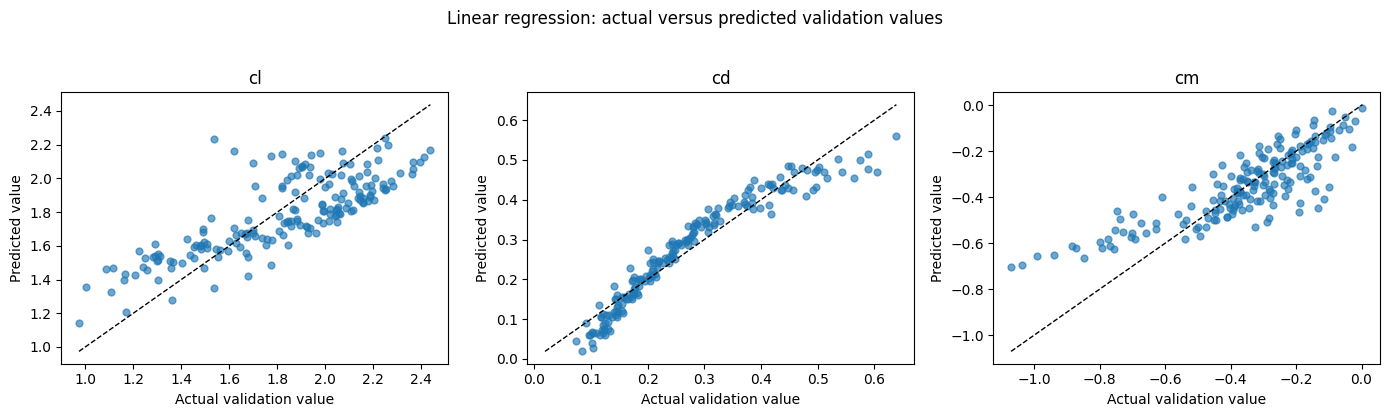

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, target in zip(axes, TARGET_NAMES):
    target_rows = saved_linear_validation.loc[saved_linear_validation["target"].eq(target)]
    axis.scatter(target_rows["actual"], target_rows["predicted"], alpha=0.65, s=24)
    limits = [
        min(target_rows["actual"].min(), target_rows["predicted"].min()),
        max(target_rows["actual"].max(), target_rows["predicted"].max()),
    ]
    axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
    axis.set_title(target)
    axis.set_xlabel("Actual validation value")
    axis.set_ylabel("Predicted value")
fig.suptitle("Linear regression: actual versus predicted validation values", y=1.03)
fig.tight_layout()
plt.show()

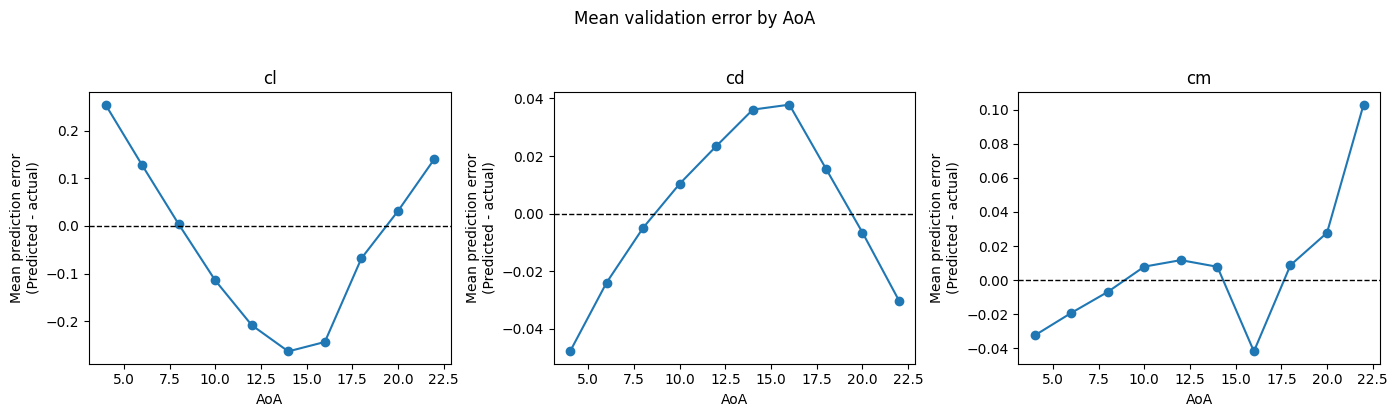

In [6]:
mean_error_by_aoa = (
    saved_linear_validation.groupby(["target", "AoA"], as_index=False)["error"].mean()
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for axis, target in zip(axes, TARGET_NAMES):
    target_errors = mean_error_by_aoa.loc[mean_error_by_aoa["target"].eq(target)]
    axis.plot(target_errors["AoA"], target_errors["error"], marker="o")
    axis.axhline(0, color="black", linestyle="--", linewidth=1)
    axis.set_title(target)
    axis.set_xlabel("AoA")
    axis.set_ylabel("Mean prediction error\n(Predicted - actual)")
fig.suptitle("Mean validation error by AoA", y=1.03)
fig.tight_layout()
plt.show()


## Model comparison

The table compares overall validation results with the AoA-only baseline. Lower MAE and RMSE are better; higher R² is better.


In [7]:
comparison = (
    saved_metrics.loc[
        saved_metrics["model"].isin(["aoa_only", MODEL_NAME])
        & saved_metrics["scope"].eq("overall"),
        ["target", "model", "MAE", "RMSE", "R2"],
    ]
    .assign(
        target=lambda frame: pd.Categorical(frame["target"], TARGET_NAMES, ordered=True),
        model=lambda frame: pd.Categorical(
            frame["model"], ["aoa_only", MODEL_NAME], ordered=True
        ),
    )
    .sort_values(["target", "model"])
)
display(comparison.reset_index(drop=True))

,target,model,MAE,RMSE,R2
0,cl,aoa_only,0.142320,0.184291,0.696275
1,cl,linear_ols,0.178400,0.209156,0.608787
2,cd,aoa_only,0.029068,0.039513,0.908863
3,cd,linear_ols,0.031666,0.038803,0.912110
4,cm,aoa_only,0.117285,0.156525,0.451207
5,cm,linear_ols,0.086190,0.118004,0.688085



## Short conclusion

Linear geometry terms improve `cd` and `cm` relative to the AoA-only baseline, but `cl` becomes worse because 'cl' rises to peak and then drops this behavious is captured by averaring whereas linear model fails to capture this non linearity. The additive model is useful as a simple geometry-aware baseline. 



## Save results

The notebook writes `results/predictions.csv`, `results/validation_metrics.csv`, and `results/models/linear_ols.joblib`. Reruns replace only `linear_ols` rows.
